# CellRank comparison with matched graph and endpoints

## The question

**When should discounted fate affinity agree with eventual absorption?**

Two fate-mapping methods can return different numbers because they answer different questions, even when both are correct. A fair comparison first holds the transition graph and fate anchors fixed; otherwise differences in preprocessing or endpoint discovery can be mistaken for differences in the probability calculation.

Here CellRank computes eventual absorption using its actual estimator, while scCS computes discounted first-hit reach. An unequal-path graph makes their relationship visible without relying on a biological ground-truth claim. This comparison explains the estimands before any claim about complete real-data workflows is attempted.

## How to read the experiment

At short horizons, inspect the preference for the nearer endpoint. At long horizons, check convergence toward the matched eventual-absorption result. Agreement is a mathematical consistency check. It does not establish equal performance for every dataset, nor does a finite-horizon difference demonstrate that either method is superior.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import scCS

SEED = 20261117
DATA = ROOT / "data" / "validation"
OUT = ROOT / "tutorial_outputs" / "validation"
OUT.mkdir(parents=True, exist_ok=True)
print("scCS", scCS.__version__)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4)})

scCS 1.0.1.dev0


## Comparison design
CellRank already computes probabilistic fate maps. We therefore first compare the estimands with the **same** transition matrix and explicit terminal anchors, avoiding differences introduced by terminal-state discovery or velocity preprocessing. This notebook calls the actual CellRank estimator, not a substitute implementation.

On the unequal-path chain from notebook 13, eventual absorption is 50/50. Finite-horizon scCS discounts the longer route more strongly. A long-horizon convergence check demonstrates the relationship between the quantities; it is not a claim of numerical or biological superiority.


In [3]:
import cellrank as cr
from benchmarks.validation.cellrank_comparison import matched_chain

print("CellRank", cr.__version__)
comparison, absorption = matched_chain()
display(comparison)
display(absorption)
comparison.to_csv(OUT / "cellrank_matched_graph.csv", index=False)

CellRank 2.4.0
INFO     Adding `adata.obs['term_states_fwd']`                                  
                `adata.obs['term_states_fwd_probs']`                            
                `.terminal_states`                                              
                `.terminal_states_probabilities`                                
                `.terminal_states_memberships                                   
             Finish`                                                            
INFO     Computing fate probabilities                                           
INFO     Adding `adata.obsm['lineages_fwd']`                                    
                `.fate_probabilities`                                           
             Finish (0.01s)                                                     


,h,DFR,CFA_A,CellRank_A,analytic_CFA_A
0,4,0.656000,0.609756,0.5,0.609756
1,16,0.887441,0.530275,0.5,0.530275
2,64,0.969584,0.507751,0.5,0.507751
3,256,0.992241,0.501949,0.5,0.501949
4,4096,0.999512,0.500122,0.5,0.500122
5,1000000,0.999998,0.500000,0.5,0.500000


,A,B
cell_0,0.5,0.5
cell_1,1.0,0.0
cell_2,0.0,1.0
cell_3,0.0,1.0
cell_4,0.0,1.0


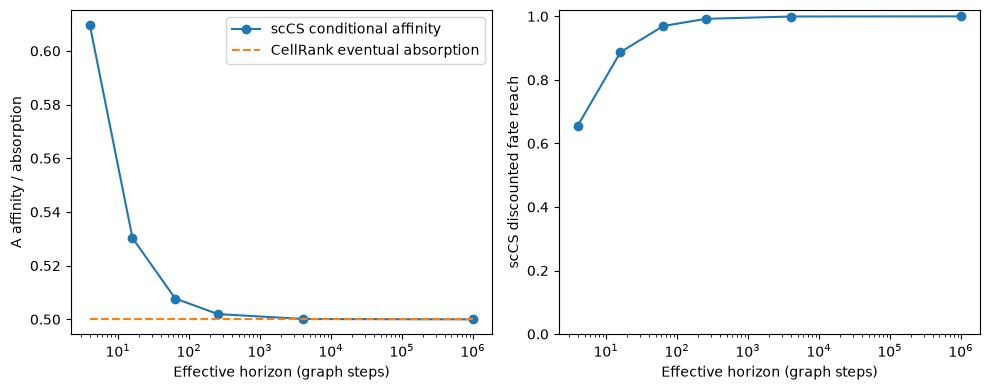

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(comparison.h, comparison.CFA_A, marker="o", label="scCS conditional affinity")
axes[0].plot(
    comparison.h, comparison.CellRank_A, linestyle="--", label="CellRank eventual absorption"
)
axes[0].set(
    xscale="log", xlabel="Effective horizon (graph steps)", ylabel="A affinity / absorption"
)
axes[0].legend()
axes[1].plot(comparison.h, comparison.DFR, marker="o")
axes[1].set(
    xscale="log",
    xlabel="Effective horizon (graph steps)",
    ylabel="scCS discounted fate reach",
    ylim=(0, 1.02),
)
fig.tight_layout()
plt.show()

## Interpretation and next benchmark tier
Finite discounted reach is a different question from eventual absorption. Conditional distributions agree in the appropriate long-horizon limit when the same reachable endpoints are used. A fair manuscript benchmark should also compare complete workflows, preprocessing choices, endpoint discovery, calibration and external outcomes. The LARRY PairScorer tutorial starts from genuine spliced/unspliced counts and estimates RNA velocity. It is a descriptive time-point comparison; it does not establish superiority on held-out clonal outcomes.


In [5]:
assert np.max(abs(comparison.CFA_A - comparison.analytic_CFA_A)) < 1e-10
assert abs(comparison.CFA_A.iloc[-1] - comparison.CellRank_A.iloc[-1]) < 1e-5
assert np.all(np.diff(comparison.DFR) >= -1e-10)
print("Matched-graph estimand and long-horizon checks passed.")

Matched-graph estimand and long-horizon checks passed.
